# Detecting Network Intrusions with a Machine Learning Pipeline (NSL-KDD)

An end-to-end machine learning workflow, turned into a reusable scikit-learn pipeline, that flags malicious network connections.

**The short version.** Every model scores close to 100% on a normal validation split, yet drops to roughly 70% F1 on the official test file, because the test file contains attack types that never appear in training. I rebuilt the validation set so it also contains unseen attack types, tuned the model and its decision threshold against that harder target, and packaged everything as one pipeline object. The final numbers are in section 9.

## 1. Project scope

**Problem.** Given the summary features of a network connection (protocol, service, byte counts, error rates, host-level traffic statistics), predict whether the connection is an attack. This is binary classification: `normal` vs `attack`.

**Why it matters.** An intrusion detection system lives or dies on attacks it has not seen before. A model that only recognises known signatures adds little over rule-based tools.

**Data.** NSL-KDD, a cleaned-up version of the KDD Cup 1999 intrusion data. It ships as two files:

| File | Rows | Role here |
|---|---|---|
| `KDDTrain+.txt` | 125,973 | training and validation |
| `KDDTest+.txt` | 22,544 | final hold-out test, used once at the end |

**Success metric.** F1 on the attack class, with recall and precision reported alongside. Accuracy alone hides how many attacks get through.

**Plan.**
1. Extract, transform and load the two files into one clean table.
2. Explore class balance and the gap between the train and test files.
3. Engineer features and design a validation set that resembles the test conditions.
4. Compare several model families.
5. Tune the best one, choose a decision threshold, and build the final pipeline.
6. Evaluate once on the test file and write up findings, limitations and next steps.

In [1]:
import json
import sys
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import PredefinedSplit, RandomizedSearchCV, train_test_split
from sklearn.model_selection import FixedThresholdClassifier
from sklearn import clone, set_config
from sklearn.tree import DecisionTreeClassifier

set_config(display="text")  # plain-text estimator reprs render everywhere, including GitHub

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import nids_pipeline as nids

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

# Chart style: light surface, recessive grid, three fixed series colours.
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


def scores(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
        "false alarm rate": float(((y_pred == 1) & (np.asarray(y_true) == 0)).sum() / (np.asarray(y_true) == 0).sum()),
    }

## 2. Extract, transform and load

The raw files have no header and use attack names (for example `neptune`, `smurf`, `guess_passwd`) as labels. The ETL step in `src/nids_pipeline.py`:

- **Extract**: reads both files with the 41 documented feature names plus the label and a difficulty score.
- **Transform**: normalises labels, maps every attack name to its family (DoS, Probe, R2L, U2R), adds the binary target `is_attack`, and fails loudly if a label is not in the mapping.
- **Load**: stacks both files with a `split` column and writes `data/processed/nsl_kdd_clean.csv.gz`.

In [2]:
df = nids.extract_transform_load()
train_df = df[df["split"] == "train"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

print(f"combined: {df.shape}, train: {train_df.shape}, test: {test_df.shape}")
print("missing values:", int(df.isnull().sum().sum()))
df[["protocol_type", "service", "flag", "src_bytes", "dst_bytes", "count", "label", "attack_category", "is_attack"]].head()

combined: (148517, 46), train: (125973, 46), test: (22544, 46)
missing values: 0


,protocol_type,service,flag,src_bytes,dst_bytes,count,label,attack_category,is_attack
0,tcp,ftp_data,SF,491,0,2,normal,normal,0
1,udp,other,SF,146,0,13,normal,normal,0
2,tcp,private,S0,0,0,123,neptune,dos,1
3,tcp,http,SF,232,8153,5,normal,normal,0
4,tcp,http,SF,199,420,30,normal,normal,0


## 3. Exploring the data

### 3.1 Class balance

The two files are not drawn from the same distribution. The test file has a higher share of attacks, and far more remote-to-local (R2L) attacks.

rows       share %      
split            train  test   train  test
attack_category                           
normal           67343  9711    53.5  43.1
dos              45927  7458    36.5  33.1
probe            11656  2421     9.3  10.7
r2l                995  2887     0.8  12.8
u2r                 52    67     0.0   0.3

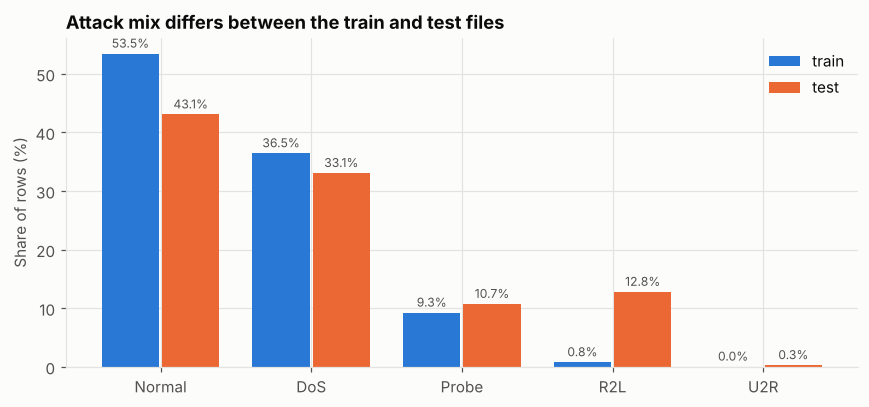

In [3]:
mix = (df.groupby(["split", "attack_category"]).size()
         .unstack(0)[["train", "test"]]
         .reindex(["normal", "dos", "probe", "r2l", "u2r"]))
share = mix / mix.sum() * 100
display(pd.concat({"rows": mix, "share %": share.round(1)}, axis=1))

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(share))
w = 0.38
for i, (split, colour) in enumerate([("train", BLUE), ("test", ORANGE)]):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), share[split], w, color=colour, label=split)
    ax.bar_label(bars, fmt="%.1f%%", padding=2, fontsize=8, color=INK_2)
ax.set_xticks(x, ["Normal", "DoS", "Probe", "R2L", "U2R"])
ax.set_ylabel("Share of rows (%)")
ax.set_title("Attack mix differs between the train and test files")
ax.legend(loc="upper right")
save(fig, "01_attack_mix.png")
plt.show()

### 3.2 The test file contains attacks the training file never shows

This is the central fact of the dataset and drives the rest of the project.

In [4]:
novel_labels = sorted(set(test_df["label"]) - set(train_df["label"]))
test_df["is_novel_attack"] = test_df["label"].isin(novel_labels)
novel_rows = int(test_df["is_novel_attack"].sum())
print(f"{len(novel_labels)} attack types appear only in the test file:")
print(", ".join(novel_labels))
print(f"\nThey make up {novel_rows:,} of {int(test_df['is_attack'].sum()):,} test attacks "
      f"({novel_rows / test_df['is_attack'].sum():.1%}).")

17 attack types appear only in the test file:
apache2, httptunnel, mailbomb, mscan, named, processtable, ps, saint, sendmail, snmpgetattack, snmpguess, sqlattack, udpstorm, worm, xlock, xsnoop, xterm

They make up 3,750 of 12,833 test attacks (29.2%).


### 3.3 Feature distributions

Byte counts and connection counts are extremely heavy-tailed: most connections move a few hundred bytes while a few move millions. A log transform compresses that range so the scaler and linear models are not dominated by outliers.

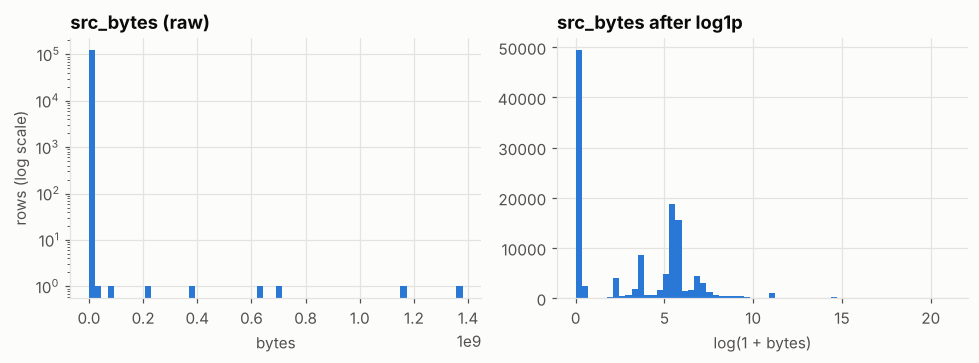

dst_bytes             290.1
num_compromised       250.1
num_root              236.9
src_bytes             190.7
num_file_creations     55.7
num_access_files       45.6
hot                    12.6
duration               11.9
dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
src = train_df["src_bytes"]
axes[0].hist(src, bins=60, color=BLUE)
axes[0].set_yscale("log")
axes[0].set_title("src_bytes (raw)")
axes[0].set_xlabel("bytes")
axes[0].set_ylabel("rows (log scale)")
axes[1].hist(np.log1p(src), bins=60, color=BLUE)
axes[1].set_title("src_bytes after log1p")
axes[1].set_xlabel("log(1 + bytes)")
save(fig, "02_src_bytes_skew.png")
plt.show()

print(train_df[nids.SKEWED_FEATURES].skew().sort_values(ascending=False).round(1).head(8))

## 4. Feature engineering and validation design

### 4.1 Features

| Group | Columns | Treatment |
|---|---|---|
| Categorical | `protocol_type`, `service`, `flag` | most-frequent imputation, one-hot encoding (unknown categories ignored) |
| Skewed counters | byte counts, connection counts, file/root activity | median imputation, `log1p`, standardisation |
| Other numeric | rates and binary flags | median imputation, standardisation |
| Dropped | `num_outbound_cmds` (constant), `difficulty` (annotation, not traffic) | not used |

All of it lives in one `ColumnTransformer`, so the exact same steps run at training and prediction time. There are no missing values today, but the imputers protect the pipeline against incomplete records in production.

In [6]:
categorical, skewed, other = nids.feature_columns(df)
features = categorical + skewed + other
print(f"{len(categorical)} categorical, {len(skewed)} skewed numeric, {len(other)} other numeric -> {len(features)} inputs")

preprocessor = nids.build_preprocessor(categorical, skewed, other)
encoded = preprocessor.fit_transform(train_df[features])
print("columns after encoding:", encoded.shape[1])

3 categorical, 12 skewed numeric, 25 other numeric -> 40 inputs


columns after encoding: 121


### 4.2 Two ways to validate

A plain random split puts the same attack types in training and validation, so it measures how well the model recognises attacks it has already seen.

The test file asks a harder question: can the model catch attacks it has never seen? To get a validation score that answers that question, I also build a **shift-aware split**: eight attack types (one to three per family) are withheld from training entirely and placed in the validation set, alongside a normal random slice of everything else. The withheld types were fixed in `src/nids_pipeline.py` before any test-set results were looked at.

Both splits are used below. The test file stays untouched until section 9.

In [7]:
X_all, y_all = train_df[features], train_df[nids.TARGET]

# (a) Standard stratified random split
X_fit_r, X_val_r, y_fit_r, y_val_r = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)

# (b) Shift-aware split: held-out attack types appear only in validation
fit_s, val_s = nids.shift_aware_split(train_df, nids.HELD_OUT_ATTACKS, seed=SEED)
X_fit_s, y_fit_s = fit_s[features], fit_s[nids.TARGET]
X_val_s, y_val_s = val_s[features], val_s[nids.TARGET]
val_is_held_out = val_s["label"].isin(nids.HELD_OUT_ATTACKS).to_numpy()

print("held-out attack types:", ", ".join(nids.HELD_OUT_ATTACKS))
print(f"random split:      fit {len(X_fit_r):,}  val {len(X_val_r):,}")
print(f"shift-aware split: fit {len(X_fit_s):,}  val {len(X_val_s):,} "
      f"({val_is_held_out.sum():,} rows of withheld attack types)")

held-out attack types: back, teardrop, nmap, warezclient, guess_passwd, imap, buffer_overflow, rootkit
random split:      fit 100,778  val 25,195
shift-aware split: fit 97,310  val 28,663 (4,335 rows of withheld attack types)


## 5. Comparing model families

Four model families, each wrapped in the same preprocessing pipeline and scored on both validation sets with the default 0.5 threshold.

In [8]:
candidates = {
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Decision tree": DecisionTreeClassifier(random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, model in candidates.items():
    start = time.time()
    p_r = nids.build_pipeline(categorical, skewed, other, clone(model)).fit(X_fit_r, y_fit_r)
    p_s = nids.build_pipeline(categorical, skewed, other, clone(model)).fit(X_fit_s, y_fit_s)
    proba_s = p_s.predict_proba(X_val_s)[:, 1]
    rows.append({
        "model": name,
        "F1 (random split)": f1_score(y_val_r, p_r.predict(X_val_r)),
        "F1 (shift-aware split)": f1_score(y_val_s, proba_s >= 0.5),
        "recall on withheld attacks": (proba_s[val_is_held_out] >= 0.5).mean(),
        "avg precision (shift-aware)": average_precision_score(y_val_s, proba_s),
        "fit time (s)": time.time() - start,
    })

comparison = pd.DataFrame(rows).set_index("model")
comparison.round(4)

,F1 (random split),F1 (shift-aware split),recall on withheld attacks,avg precision (shift-aware),fit time (s)
model,,,,,
Logistic regression,0.9829,0.9187,0.4962,0.9562,4.6266
Decision tree,0.9984,0.8869,0.2925,0.9041,4.3997
Random forest,0.9988,0.8916,0.3188,0.9801,16.8045
Gradient boosting,0.9991,0.8868,0.2911,0.9802,10.6784


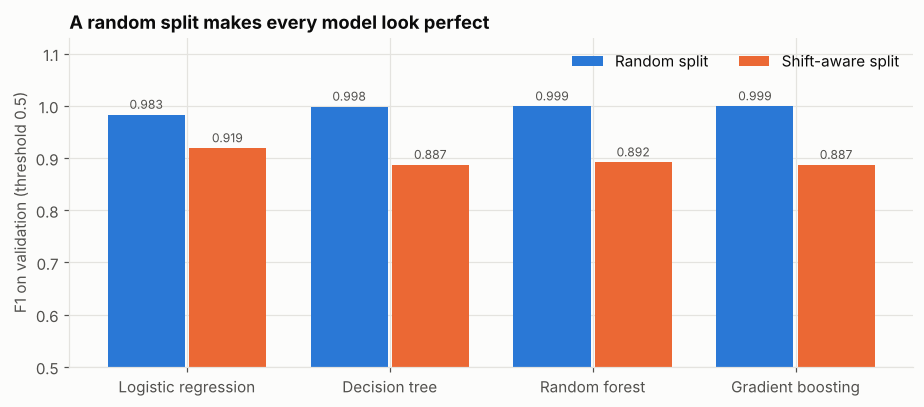

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(comparison))
w = 0.38
for i, (col, colour, label) in enumerate([
        ("F1 (random split)", BLUE, "Random split"),
        ("F1 (shift-aware split)", ORANGE, "Shift-aware split")]):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), comparison[col], w, color=colour, label=label)
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8, color=INK_2)
ax.set_xticks(x, comparison.index)
ax.set_ylim(0.5, 1.13)
ax.set_ylabel("F1 on validation (threshold 0.5)")
ax.set_title("A random split makes every model look perfect")
ax.legend(loc="upper right", ncol=2)
save(fig, "03_model_comparison.png")
plt.show()

**Reading the comparison.**

- On the random split every model scores close to perfect. That split cannot tell the models apart, and it badly overstates real-world performance.
- On the shift-aware split the scores drop and spread out, and recall on the withheld attack types falls sharply at the default threshold.
- The tree ensembles have the best average precision on the shift-aware split. Average precision ignores the threshold, which means a better threshold could recover a lot of the missed attacks.

I take the **random forest** forward: it has a strong threshold-free score on the shift-aware split, it trains in seconds, and its feature importances are easy to explain.

## 6. Hyperparameter tuning

`RandomizedSearchCV` searches the random forest's hyperparameters. Instead of k-fold cross-validation, a `PredefinedSplit` makes the search score every candidate on the shift-aware validation set, so the search optimises for unseen attacks rather than familiar ones. The scoring metric is average precision, because the threshold is chosen separately in the next step.

In [10]:
X_search = pd.concat([X_fit_s, X_val_s])
y_search = pd.concat([y_fit_s, y_val_s])
fold = np.r_[np.full(len(X_fit_s), -1), np.zeros(len(X_val_s))]

search_space = {
    "model__n_estimators": [100, 200, 300],
    "model__max_features": ["sqrt", "log2", 0.3],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_depth": [None, 20, 30],
    "model__class_weight": [None, "balanced"],
}
search = RandomizedSearchCV(
    nids.build_pipeline(categorical, skewed, other,
                        RandomForestClassifier(n_jobs=-1, random_state=SEED)),
    search_space, n_iter=10, scoring="average_precision",
    cv=PredefinedSplit(fold), refit=False, random_state=SEED)

start = time.time()
search.fit(X_search, y_search)
print(f"search took {time.time() - start:.0f}s")
print("best average precision:", round(search.best_score_, 4))
best_params = search.best_params_
best_params

search took 169s
best average precision: 0.9945


{'model__n_estimators': 300,
 'model__min_samples_leaf': 1,
 'model__max_features': 'sqrt',
 'model__max_depth': 20,
 'model__class_weight': None}

In [11]:
results = pd.DataFrame(search.cv_results_)
cols = [c for c in results.columns if c.startswith("param_model__")]
(results[cols + ["mean_test_score"]]
   .rename(columns=lambda c: c.replace("param_model__", ""))
   .sort_values("mean_test_score", ascending=False)
   .round(4))

,n_estimators,min_samples_leaf,max_features,max_depth,class_weight,mean_test_score
5,300,1,sqrt,20,NaN,0.9945
1,200,1,sqrt,20,balanced,0.9891
4,200,2,log2,None,balanced,0.9842
6,300,1,0.3,None,balanced,0.9826
7,100,5,0.3,20,NaN,0.9826
3,200,1,sqrt,30,NaN,0.9801
8,200,1,0.3,None,balanced,0.9797
2,300,2,0.3,20,balanced,0.9744
9,100,1,log2,30,balanced,0.9691
0,300,2,0.3,30,balanced,0.9683


## 7. Choosing the decision threshold

A random forest's probability is the share of trees voting "attack". The default rule (flag when at least half the trees agree) is tuned for familiar traffic. For new attack types only a few trees fire, so the right threshold is much lower.

The threshold is picked to maximise F1 on the shift-aware validation set, using a model trained only on the training part of that split.

chosen threshold: 0.0050  (validation F1 0.9626, vs 0.8960 at 0.5)
in plain terms: flag a connection when at least 2 of 300 trees vote 'attack' (default rule: 150)
recall on withheld attacks: 0.344 at 0.5 -> 0.876 at the chosen threshold


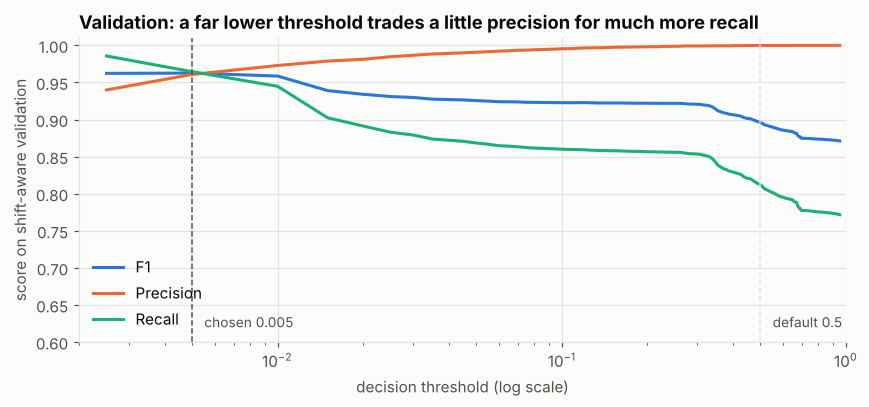

In [12]:
tuned = nids.build_pipeline(categorical, skewed, other,
                            RandomForestClassifier(n_jobs=-1, random_state=SEED))
tuned.set_params(**best_params).fit(X_fit_s, y_fit_s)
proba_val = tuned.predict_proba(X_val_s)[:, 1]

threshold, val_f1 = nids.best_f1_threshold(y_val_s, proba_val)
n_trees = best_params["model__n_estimators"]
print(f"chosen threshold: {threshold:.4f}  (validation F1 {val_f1:.4f}, "
      f"vs {f1_score(y_val_s, proba_val >= 0.5):.4f} at 0.5)")
print(f"in plain terms: flag a connection when at least {int(np.ceil(threshold * n_trees))} "
      f"of {n_trees} trees vote 'attack' (default rule: {n_trees // 2})")
print(f"recall on withheld attacks: {(proba_val[val_is_held_out] >= 0.5).mean():.3f} at 0.5 -> "
      f"{(proba_val[val_is_held_out] >= threshold).mean():.3f} at the chosen threshold")

grid = np.r_[0.0025, np.linspace(0.005, 0.95, 190)]
curve = pd.DataFrame({
    "threshold": grid,
    "f1": [f1_score(y_val_s, proba_val >= t) for t in grid],
    "precision": [precision_score(y_val_s, proba_val >= t, zero_division=0) for t in grid],
    "recall": [recall_score(y_val_s, proba_val >= t) for t in grid],
})

fig, ax = plt.subplots(figsize=(8, 3.8))
for col, colour in [("f1", BLUE), ("precision", ORANGE), ("recall", AQUA)]:
    ax.plot(curve["threshold"], curve[col], color=colour, lw=2, label=col.capitalize())
ax.axvline(threshold, color=INK_2, lw=1, ls="--")
ax.axvline(0.5, color=GRID, lw=1, ls="--")
ax.annotate(f"chosen {threshold:.3f}", (threshold, 0.62), xytext=(8, 0),
            textcoords="offset points", color=INK_2, fontsize=9)
ax.annotate("default 0.5", (0.5, 0.62), xytext=(8, 0),
            textcoords="offset points", color=INK_2, fontsize=9)
ax.set_xscale("log")
ax.set_xlim(0.002, 1)
ax.set_xlabel("decision threshold (log scale)")
ax.set_ylabel("score on shift-aware validation")
ax.set_ylim(0.6, 1.01)
ax.set_title("Validation: a far lower threshold trades a little precision for much more recall")
ax.legend(loc="lower left")
save(fig, "04_threshold_curve.png")
plt.show()

### 7.1 Sensitivity check

The result should not hinge on which eight attack types were withheld. Repeating the threshold selection with a second, disjoint set of withheld types (same tuned hyperparameters):

In [13]:
fit_alt, val_alt = nids.shift_aware_split(train_df, nids.HELD_OUT_ATTACKS_ALT, seed=SEED)
alt_model = nids.build_pipeline(categorical, skewed, other,
                                RandomForestClassifier(n_jobs=-1, random_state=SEED))
alt_model.set_params(**best_params).fit(fit_alt[features], fit_alt[nids.TARGET])
proba_alt = alt_model.predict_proba(val_alt[features])[:, 1]
threshold_alt, val_f1_alt = nids.best_f1_threshold(val_alt[nids.TARGET], proba_alt)

print("alternative withheld types:", ", ".join(nids.HELD_OUT_ATTACKS_ALT))
print(f"threshold {threshold_alt:.4f} (validation F1 {val_f1_alt:.4f}) "
      f"vs primary threshold {threshold:.4f}")

alternative withheld types: smurf, pod, ipsweep, warezmaster, ftp_write, multihop, loadmodule, perl
threshold 0.0250 (validation F1 0.9890) vs primary threshold 0.0050


Both withheld sets point the same way: the best threshold sits far below 0.5. The exact value moves with the choice of withheld attacks, so it is a tuned setting to revisit as new attack data arrives, not a constant. The primary threshold is used from here on.

## 8. The final pipeline

The production model is a single object:

1. `ColumnTransformer` preprocessing (section 4.1)
2. `RandomForestClassifier` with the tuned hyperparameters (section 6)
3. wrapped in `FixedThresholdClassifier`, so `.predict()` applies the chosen threshold (section 7)

It is refit on the full training file, saved with `joblib`, and its configuration is written to `reports/model_config.json` so `train.py` can rebuild it without the notebook.

In [14]:
final_model = FixedThresholdClassifier(
    nids.build_pipeline(categorical, skewed, other,
                        RandomForestClassifier(n_jobs=-1, random_state=SEED)).set_params(**best_params),
    threshold=threshold, response_method="predict_proba")
final_model.fit(X_all, y_all)
print(final_model)

FixedThresholdClassifier(estimator=Pipeline(steps=[('preprocess',
                                                    ColumnTransformer(transformers=[('cat',
                                                                                     Pipeline(steps=[('imputer',
                                                                                                      SimpleImputer(strategy='most_frequent')),
                                                                                                     ('ohe',
                                                                                                      OneHotEncoder(handle_unknown='ignore',
                                                                                                                    sparse_output=False))]),
                                                                                     ['protocol_type',
                                                                                      'serv

In [15]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(final_model, MODEL_DIR / "nids_pipeline.joblib", compress=3)

config = {
    "model": "RandomForestClassifier",
    "hyperparameters": {k.replace("model__", ""): v for k, v in best_params.items()},
    "threshold": threshold,
    "held_out_attacks": nids.HELD_OUT_ATTACKS,
    "seed": SEED,
}
(PROJECT_ROOT / "reports" / "model_config.json").write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

{
  "model": "RandomForestClassifier",
  "hyperparameters": {
    "n_estimators": 300,
    "min_samples_leaf": 1,
    "max_features": "sqrt",
    "max_depth": 20,
    "class_weight": null
  },
  "threshold": 0.005,
  "held_out_attacks": [
    "back",
    "teardrop",
    "nmap",
    "warezclient",
    "guess_passwd",
    "imap",
    "buffer_overflow",
    "rootkit"
  ],
  "seed": 42
}


## 9. Final evaluation on the test file

The test file is used exactly once, here. For comparison, the same fitted forest is also scored with the default 0.5 threshold.

In [16]:
X_test, y_test = test_df[features], test_df[nids.TARGET]
proba_test = final_model.estimator_.predict_proba(X_test)[:, 1]
pred_default = (proba_test >= 0.5).astype(int)
pred_final = final_model.predict(X_test)

test_results = pd.DataFrame({
    "default threshold (0.5)": scores(y_test, pred_default),
    f"tuned threshold ({threshold:.3f})": scores(y_test, pred_final),
}).T
test_results.round(4)

,accuracy,precision,recall,f1,false alarm rate
default threshold (0.5),0.7629,0.9669,0.6041,0.7436,0.0273
tuned threshold (0.005),0.9236,0.8923,0.9846,0.9362,0.1570


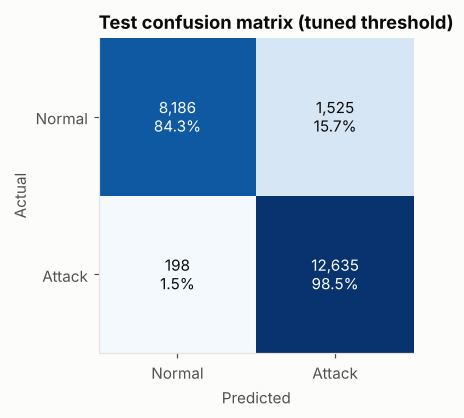

In [17]:
cm = confusion_matrix(y_test, pred_final)
cm_pct = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(4.6, 3.9))
ax.imshow(cm_pct, cmap="Blues", vmin=0, vmax=1)
ax.grid(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]:,}\n{cm_pct[i, j]:.1%}", ha="center", va="center",
                color="white" if cm_pct[i, j] > 0.6 else INK, fontsize=10)
ax.set_xticks([0, 1], ["Normal", "Attack"])
ax.set_yticks([0, 1], ["Normal", "Attack"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Test confusion matrix (tuned threshold)")
save(fig, "05_confusion_matrix.png")
plt.show()

### 9.1 Where the errors are

Recall by attack family, split into attack types the model trained on and attack types that only exist in the test file.

rows  recall_default  recall_tuned
attack_category seen in training                                    
dos             novel             1717           0.066         0.999
                seen              5741           0.997         1.000
probe           novel             1315           0.506         1.000
                seen              1106           1.000         1.000
r2l             novel              688           0.003         0.762
                seen              2199           0.060         0.986
u2r             novel               30           0.200         1.000
                seen                37           0.108         0.946

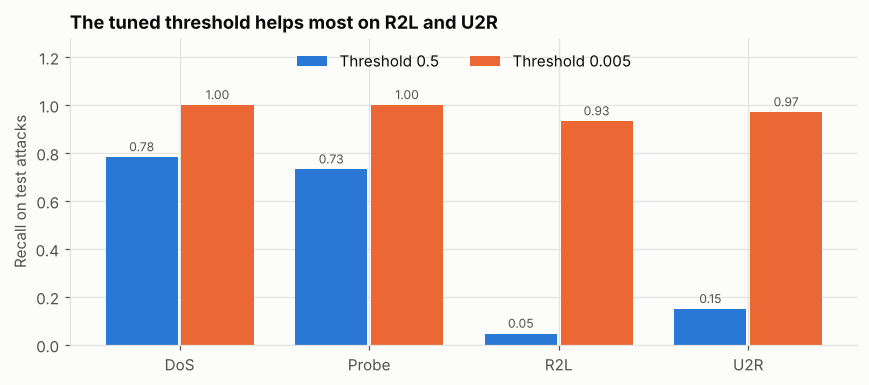

In [18]:
attacks = test_df[test_df["is_attack"] == 1].copy()
attacks["caught_default"] = pred_default[attacks.index] == 1
attacks["caught_final"] = pred_final[attacks.index] == 1
attacks["seen in training"] = np.where(attacks["is_novel_attack"], "novel", "seen")

by_family = (attacks.groupby(["attack_category", "seen in training"])
                    .agg(rows=("label", "size"),
                         recall_default=("caught_default", "mean"),
                         recall_tuned=("caught_final", "mean")))
display(by_family.round(3))

fam = attacks.groupby("attack_category")[["caught_default", "caught_final"]].mean().reindex(["dos", "probe", "r2l", "u2r"])
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(fam))
w = 0.38
for i, (col, colour, label) in enumerate([("caught_default", BLUE, "Threshold 0.5"),
                                           ("caught_final", ORANGE, f"Threshold {threshold:.3f}")]):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), fam[col], w, color=colour, label=label)
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=8, color=INK_2)
ax.set_xticks(x, ["DoS", "Probe", "R2L", "U2R"])
ax.set_ylim(0, 1.28)
ax.set_ylabel("Recall on test attacks")
ax.set_title("The tuned threshold helps most on R2L and U2R")
ax.legend(loc="upper center", ncol=2)
save(fig, "06_recall_by_family.png")
plt.show()

### 9.2 What the model relies on

Impurity-based importances from the forest, with one-hot columns summed back to their original feature.

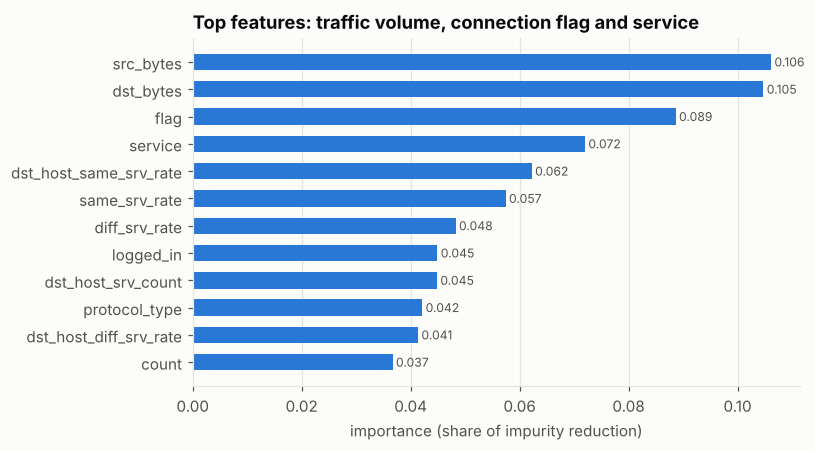

src_bytes                 0.1061
dst_bytes                 0.1047
flag                      0.0886
service                   0.0720
dst_host_same_srv_rate    0.0622
same_srv_rate             0.0574
diff_srv_rate             0.0482
logged_in                 0.0449
dst_host_srv_count        0.0448
protocol_type             0.0421
dst_host_diff_srv_rate    0.0413
count                     0.0367
dtype: float64

In [19]:
forest = final_model.estimator_.named_steps["model"]
names = final_model.estimator_.named_steps["preprocess"].get_feature_names_out()
imp = pd.Series(forest.feature_importances_, index=names)
original = imp.index.str.split("__").str[1]
for c in categorical:
    original = np.where(pd.Series(original).str.startswith(c + "_"), c, original)
importance = imp.groupby(original).sum().sort_values(ascending=False)

top = importance.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
for y_pos, v in enumerate(top.values):
    ax.text(v, y_pos, f" {v:.3f}", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("importance (share of impurity reduction)")
ax.set_title("Top features: traffic volume, connection flag and service")
ax.grid(axis="y", visible=False)
save(fig, "07_feature_importance.png")
plt.show()
importance.head(12).round(4)

## 10. Findings

1. **A random validation split is misleading on this data.** Every model scored close to perfect on it, yet the tuned forest at its default threshold reached only 0.74 F1 on the test file. About 29% of test attacks belong to types that never appear in training.
2. **Validating on withheld attack types gives a realistic target.** Recall on the withheld types was only 29-50% at the default threshold, which is the same failure the test file exposes.
3. **The decision threshold mattered more than the choice of model.** With the threshold tuned on the shift-aware split, the same forest went from 0.74 to 0.94 F1 on the test file, and from 60% to 98% recall.
4. **Almost all of the gain is on unseen attack types.** Recall on novel DoS attacks rose from 7% to almost 100%, on novel probes from 51% to 100%, and on R2L attacks from under 10% to 76-99%.
5. **The price is false alarms.** The share of normal test connections flagged as attacks rose from about 3% to about 16%. That is the real trade-off this model makes, and section 11 discusses it.
6. **The most useful signals** are traffic volume (`src_bytes`, `dst_bytes`), the connection flag, the service, and host-level service rates, which matches how analysts reason about scans and floods.

## 11. Conclusion, limitations and next steps

**Conclusion.** The pipeline turns raw connection records into an attack/normal decision in one `fit`/`predict` object, and it was tuned for the condition that matters most for intrusion detection: attacks the model has not seen before.

**Limitations.**
- NSL-KDD is synthetic traffic from 1998. It is a standard benchmark, not a picture of modern networks, so these numbers will not transfer directly to live traffic.
- The tuned threshold depends on which attack types are withheld (section 7.1). It should be re-tuned whenever the attack mix changes.
- The tuned threshold flags roughly one in six normal connections. In a security operations centre that is a heavy alert load, so in practice the threshold should be set against the team's alert budget (a target false-alarm rate), not F1 alone. The notebook shows the trade-off; it does not pick the operational point.
- The model flags attacks but does not name the attack family.

**Next steps.**
- Validate on a modern dataset such as CIC-IDS2017 or UNSW-NB15.
- Add an anomaly-detection component (for example an isolation forest trained on normal traffic only) to catch attacks that look unlike anything labelled.
- Move from binary to multi-class output so alerts carry the attack family.
- Calibrate probabilities and pick the threshold from a target false-positive rate.
- Serve `models/nids_pipeline.joblib` behind a small API and monitor drift in the input features.